# Data format vs. token usage: Qwen vs. Claude

**Question:** does the **format of the data** in a prompt (CSV, XML, or prose) change token usage the same way for different models?

- **Same experiment and analyses as eda1:** same tasks, prompts, temperature (0.7), system prompt, and tests; only the model differs.
- **Models:** `qwen2.5-coder:7b` (local, Ollama) and `claude-haiku-4-5` (Anthropic API, no extended thinking).
- **Data:** `data/results.csv` (Qwen) and `data/results_claude.csv` (Claude).

In [1]:
import ast
import base64
import html
import json
import re
import sys
import textwrap
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, Markdown

sys.path.insert(0, "../src")
from evaluate import extract_code

QWEN, CLAUDE = "qwen2.5-coder:7b", "claude-haiku-4-5"
MODELS = [QWEN, CLAUDE]
SHORT = {QWEN: "qwen", CLAUDE: "claude"}
RAW_DIRS = {QWEN: Path("../data/raw"), CLAUDE: Path("../data/raw_claude")}

DATA_FORMATS = ["csv", "xml", "prose"]
DATA_COLORS = {"csv": "#008300", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "xml": "s", "prose": "D"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

responses = pd.concat([pd.read_csv("../data/results.csv"), pd.read_csv("../data/results_claude.csv")],
                      ignore_index=True)
responses = responses[responses["model"].isin(MODELS)].copy()
responses["total_tokens"] = responses["input_tokens"] + responses["output_tokens"]

is_parse = responses["task_id"].str.endswith("_parse")
copy_rows = responses[~is_parse].copy()    # sections 1-4: the code contains the data
parse_rows = responses[is_parse].copy()    # sections 5-7: the code receives the data as text
valid = copy_rows[copy_rows["passed_all"]].copy()   # code runs and contains all the data
for model in MODELS:
    m = responses["model"] == model
    print(f"{model}: {(~is_parse & m).sum()} copy rows ({(valid['model'] == model).sum()} valid), "
          f"{(is_parse & m).sum()} parse rows")
responses.head()

qwen2.5-coder:7b: 180 copy rows (158 valid), 180 parse rows
claude-haiku-4-5: 180 copy rows (157 valid), 180 parse rows


,task_id,format,data_format,run,model,input_tokens,output_tokens,tests_passed,tests_total,passed_all,stop_reason,timestamp,total_tokens
0,t12_gold_lead,informal,xml,1,qwen2.5-coder:7b,1158,1010,2,2,True,stop,2026-10-14T17:20:11+00:00,2168
1,t11_side_winrate,informal,csv,1,qwen2.5-coder:7b,517,714,2,2,True,stop,2026-10-14T17:20:23+00:00,1231
2,t16_support_vision,structured,csv,1,qwen2.5-coder:7b,584,1178,2,2,True,stop,2026-10-14T17:20:42+00:00,1762
3,t11_side_winrate,structured,csv,1,qwen2.5-coder:7b,532,1016,2,2,True,stop,2026-10-14T17:20:58+00:00,1548
4,t16_support_vision,structured,xml,1,qwen2.5-coder:7b,1366,1140,2,2,True,stop,2026-10-14T17:21:17+00:00,2506


In [2]:
def safe(model):
    return model.replace(":", "-").replace("/", "-")

def raw_path(r):
    return RAW_DIRS[r.model] / f"{r.task_id}__{r.format}__{r.data_format}__run{r.run}__{safe(r.model)}.txt"

HAS_RAW = {model: any(RAW_DIRS[model].glob(f"*__{safe(model)}.txt")) for model in MODELS}

EDA1 = json.loads(Path("eda1.ipynb").read_text(encoding="utf-8"))

def eda1_saved_output(heading):
    """The saved outputs of eda1.ipynb's cells under the markdown heading starting with `heading`."""
    outputs, inside = [], False
    for cell in EDA1["cells"]:
        if cell["cell_type"] == "markdown":
            inside = "".join(cell["source"]).startswith(heading)
            continue
        for out in cell.get("outputs", []) if inside else []:
            data = out.get("data", {})
            if "image/png" in data:
                outputs.append(Image(base64.b64decode(data["image/png"])))
            elif "text/html" in data:
                outputs.append(HTML("".join(data["text/html"])))
            elif "text" in out:
                outputs.append(Markdown(f"`{''.join(out['text']).strip()}`"))
    return outputs

def for_each_model(section, heading):
    """Run `section(model)` per model, or show eda1's saved output if the raw replies are missing."""
    for model in MODELS:
        display(Markdown(f"### {model}"))
        if HAS_RAW[model]:
            section(model)
        else:
            display(Markdown("*Raw replies aren't on this machine; saved output from eda1.ipynb:*"))
            for out in eda1_saved_output(heading):
                display(out)

print("raw replies available:", HAS_RAW)

raw replies available: {'qwen2.5-coder:7b': False, 'claude-haiku-4-5': True}


In [3]:
TASKS_DIR = Path("../tasks")
TASK_IDS = sorted(p.name for p in TASKS_DIR.glob("t*") if p.is_dir() and not p.name.endswith("_parse"))

def read_task_file(task_id, name):
    return (TASKS_DIR / task_id / name).read_text(encoding="utf-8")

print("Tasks:", ", ".join(TASK_IDS))

Tasks: t11_side_winrate, t12_gold_lead, t13_objectives, t14_mid_kda, t15_jungle_picks, t16_support_vision


In [4]:
EXAMPLE_DATA_TASK = "t11_side_winrate"

def preview(text, data_format, n=4):
    """The first n rows of a data block (prose rows are sentences, so cut by characters instead)."""
    if data_format == "prose":
        return textwrap.fill(text[:420], 60) + " ..."
    lines = text.splitlines()
    return "\n".join(lines[:n + 1]) + "\n..."   # +1 for the CSV header / opening <rows> tag

columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>data_{d}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(preview(read_task_file(EXAMPLE_DATA_TASK, f"data_{d}.txt"), d))}</pre></td>'
    for d in DATA_FORMATS
)
display(Markdown(f"#### `{EXAMPLE_DATA_TASK}`: first rows in each data format"))
display(HTML(f"<table><tr>{columns}</tr></table>"))

#### `t11_side_winrate`: first rows in each data format

"data_csv.txtgame,team,side,result,game_minutes G01,DN Freecs,blue,loss,34.1 G01,Dplus KIA,red,win,34.1 G02,BNK FEARX,blue,loss,40.1 G02,Gen.G,red,win,40.1 ...",data_xml.txt<rows> <row><game>G01</game><team>DN Freecs</team><side>blue</side><result>loss</result><game_minutes>34.1</game_minutes></row> <row><game>G01</game><team>Dplus KIA</team><side>red</side><result>win</result><game_minutes>34.1</game_minutes></row> <row><game>G02</game><team>BNK FEARX</team><side>blue</side><result>loss</result><game_minutes>40.1</game_minutes></row> <row><game>G02</game><team>Gen.G</team><side>red</side><result>win</result><game_minutes>40.1</game_minutes></row> ...,"data_prose.txtIn game G01, DN Freecs played on the blue side and lost; the game lasted 34.1 minutes. In game G01, Dplus KIA played on the red side and won; the game lasted 34.1 minutes. In game G02, BNK FEARX played on the blue side and lost; the game lasted 40.1 minutes. In game G02, Gen.G played on the red side and won; the game lasted 40.1 minutes. In game G03, Dplus KIA played on the blue side and won; the game lasted 27.5 min ..."


In [5]:
data_rows = []
for task_id in TASK_IDS:
    row = {"task_id": task_id, "rows": len(json.loads(read_task_file(task_id, "sample.json")))}
    for d in DATA_FORMATS:
        row[f"{d} chars"] = len(read_task_file(task_id, f"data_{d}.txt"))
    data_rows.append(row)
data_table = pd.DataFrame(data_rows).set_index("task_id")

for model in MODELS:
    input_by_format = (copy_rows[copy_rows["model"] == model]
                       .groupby(["task_id", "data_format"])["input_tokens"].mean().unstack())
    for d in DATA_FORMATS:
        data_table[f"{d} input tokens ({SHORT[model]})"] = input_by_format[d].round(0)
data_table

,rows,csv chars,xml chars,prose chars,csv input tokens (qwen),xml input tokens (qwen),prose input tokens (qwen),csv input tokens (claude),xml input tokens (claude),prose input tokens (claude)
task_id,,,,,,,,,,
t11_side_winrate,20,627,2487,1752,524.0,1062.0,722.0,526.0,1142.0,735.0
t12_gold_lead,20,617,2477,2062,515.0,1168.0,825.0,490.0,1194.0,817.0
t13_objectives,20,794,3397,2412,558.0,1417.0,855.0,578.0,1390.0,922.0
t14_mid_kda,20,801,3287,1812,574.0,1356.0,716.0,629.0,1323.0,837.0
t15_jungle_picks,20,459,2084,1209,380.0,894.0,498.0,433.0,893.0,570.0
t16_support_vision,20,803,3639,2064,572.0,1354.0,787.0,562.0,1490.0,844.0


## 1. Tokens by data format

In [6]:
order = [(model, d) for model in MODELS for d in DATA_FORMATS]
(valid.groupby(["model", "data_format"])[["input_tokens", "output_tokens", "total_tokens"]]
 .agg(["mean", "median"]).round(0).loc[order])

input_tokens         output_tokens          \
                                     mean  median          mean  median   
model            data_format                                              
qwen2.5-coder:7b csv                529.0   546.0        1043.0  1114.0   
                 xml               1229.0  1342.0        1116.0  1140.0   
                 prose              723.0   729.0         836.0   786.0   
claude-haiku-4-5 csv                536.0   538.0        1069.0  1044.0   
                 xml               1239.0  1208.0        1387.0  1340.0   
                 prose              786.0   828.0        1341.0  1344.0   

                             total_tokens          
                                     mean  median  
model            data_format                       
qwen2.5-coder:7b csv               1572.0  1647.0  
                 xml               2345.0  2488.0  
                 prose             1558.0  1537.0  
claude-haiku-4-5 csv               1604.0  1495.0  
                 xml               2626.0  2686.0  
                 prose             2127.0  2206.0

## 2. Output tokens by data format

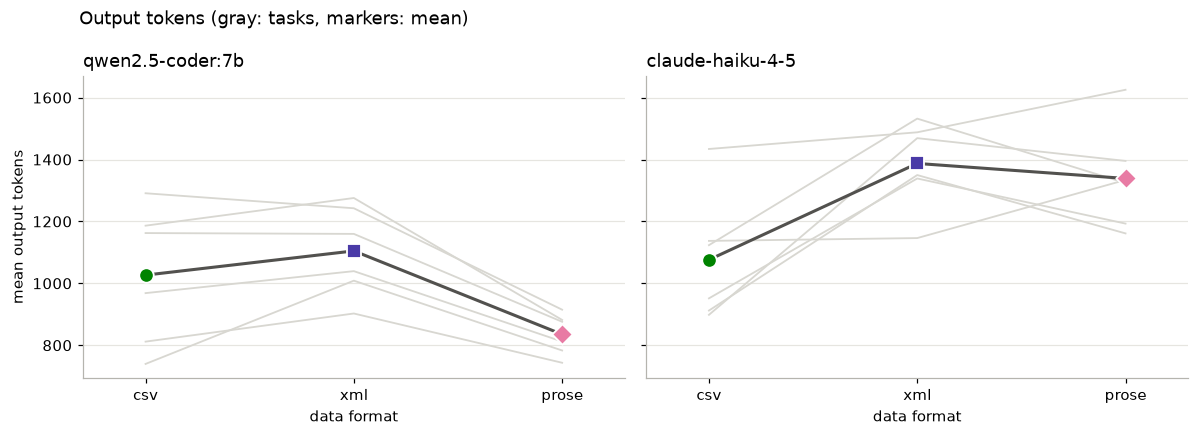

In [7]:
x = np.arange(len(DATA_FORMATS))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model in zip(axes, MODELS):
    sub = valid[valid["model"] == model]
    per_task = sub.groupby(["task_id", "data_format"])["output_tokens"].mean().unstack()[DATA_FORMATS]
    for task_id, row in per_task.iterrows():
        ax.plot(x, row.values, color="#d8d7d1", linewidth=1.2, zorder=1)
    ax.plot(x, per_task.mean().values, color="#52514e", linewidth=2, zorder=2)
    for i, d in enumerate(DATA_FORMATS):
        ax.scatter(i, per_task[d].mean(), s=90, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
                   edgecolor="white", linewidth=1.2)
    ax.set_xticks(x, DATA_FORMATS)
    ax.set_xlim(-0.3, len(DATA_FORMATS) - 0.7)
    ax.set_xlabel("data format")
    ax.set_title(model, loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mean output tokens")
fig.suptitle("Output tokens (gray: tasks, markers: mean)", x=0.07, ha="left")
fig.tight_layout()
plt.show()

## 3. Output vs input tokens

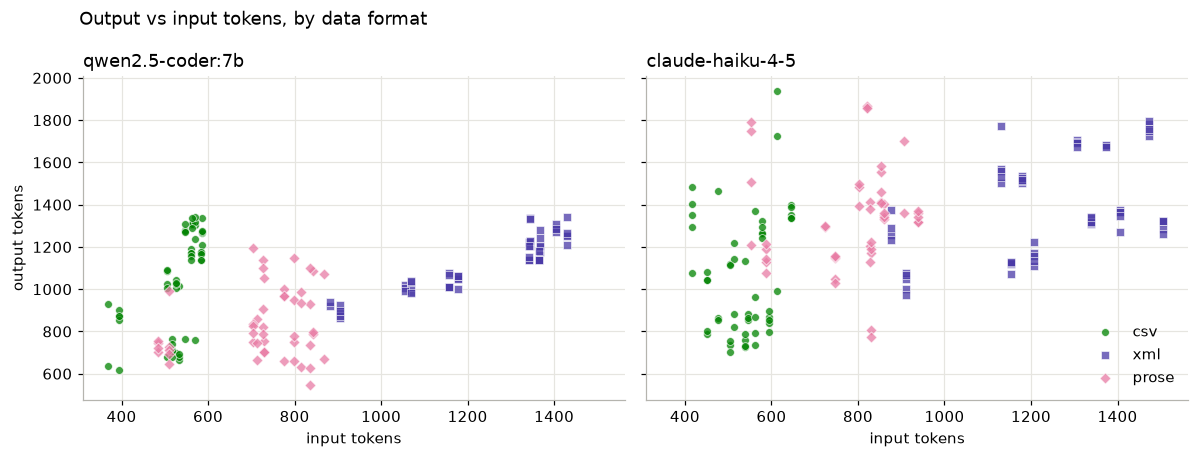

model,qwen2.5-coder:7b,claude-haiku-4-5
data_format,,
csv,1.97,2.02
xml,0.92,1.13
prose,1.16,1.73


In [8]:
valid["output_per_input"] = valid["output_tokens"] / valid["input_tokens"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, model in zip(axes, MODELS):
    for d in DATA_FORMATS:
        sub_rows = valid[(valid["model"] == model) & (valid["data_format"] == d)]
        ax.scatter(sub_rows["input_tokens"], sub_rows["output_tokens"], s=26, alpha=0.75, color=DATA_COLORS[d],
                   marker=DATA_MARKERS[d], edgecolor="white", linewidth=0.5, label=d)
    ax.set_xlabel("input tokens")
    ax.set_title(model, loc="left")
axes[0].set_ylabel("output tokens")
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Output vs input tokens, by data format", x=0.07, ha="left")
fig.tight_layout()
plt.show()

ratio = valid.groupby(["model", "task_id", "data_format"])["output_per_input"].mean()
ratio.groupby(["data_format", "model"]).mean().unstack("model").loc[DATA_FORMATS, MODELS].round(2)

## 4. How the model stored the data

Reads the saved responses in `data/raw/` (Qwen, local only) and `data/raw_claude/` (Claude).

In [9]:
def storage_style(code_text):
    """How the model wrote the 20 rows into its code: dicts with a key per value, or bare tuples/lists."""
    dict_rows = code_text.count('{"') + code_text.count("{'")          # {"team": ..., "side": ...}
    tuple_rows = sum(line.strip()[:2] in ('("', "('", '["', "['")      # ("DN Freecs", "blue", ...)
                     for line in code_text.splitlines())
    if dict_rows >= 15:
        return "dicts with keys"
    if tuple_rows >= 15:
        return "tuples/lists"
    return "other"

def section4(model):
    style_rows = []
    for path in RAW_DIRS[model].glob(f"*__{safe(model)}.txt"):
        task_id, fmt, data_format, run, _ = path.stem.split("__")
        if data_format not in DATA_FORMATS:
            continue
        code_text = extract_code(path.read_text(encoding="utf-8"))
        style_rows.append({"task_id": task_id, "format": fmt, "data_format": data_format,
                           "run": int(run.removeprefix("run")), "style": storage_style(code_text)})
    styles = pd.DataFrame(style_rows).merge(valid[valid["model"] == model],
                                            on=["task_id", "format", "data_format", "run"])
    display(pd.crosstab(styles["data_format"], styles["style"]).loc[DATA_FORMATS])
    display(styles.groupby("style")["output_tokens"].agg(["count", "mean"]).round(0))
    display(styles.groupby(["data_format", "style"])["output_tokens"].agg(["count", "mean"]).round(0).loc[DATA_FORMATS])

for_each_model(section4, "## 4.")

### qwen2.5-coder:7b

*Raw replies aren't on this machine; saved output from eda1.ipynb:*

style,dicts with keys,other,tuples/lists
data_format,,,
csv,42,0,14
xml,54,0,0
prose,17,2,29


,count,mean
style,,
dicts with keys,113,1118.0
other,2,606.0
tuples/lists,43,726.0


### claude-haiku-4-5

style,dicts with keys,other,tuples/lists
data_format,,,
csv,27,9,17
xml,33,23,0
prose,39,7,2


,count,mean
style,,
dicts with keys,99,1314.0
other,39,1368.0
tuples/lists,19,800.0


count    mean
data_format style                         
csv         dicts with keys     27  1304.0
            other                9   866.0
            tuples/lists        17   801.0
xml         dicts with keys     33  1248.0
            other               23  1586.0
prose       dicts with keys     39  1377.0
            other                7  1298.0
            tuples/lists         2   790.0

## 5. Parse version: tokens by data format

The code receives the data as text (`q1(text)`) instead of containing it.

In [10]:
def prompt_names(task_id):
    for node in ast.parse((TASKS_DIR / task_id / "test_solution.py").read_text(encoding="utf-8")).body:
        if isinstance(node, ast.Assign) and node.targets[0].id == "PROMPT_NAMES":
            return ast.literal_eval(node.value)

def normalize(text):
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()

def saved_code(r):
    return extract_code(raw_path(r).read_text(encoding="utf-8"))

parse_by_model, attempts_by_model = {}, {}
for model in MODELS:
    if not HAS_RAW[model]:
        continue
    rows = parse_rows[parse_rows["model"] == model].copy()
    rows["code_text"] = [saved_code(r) for r in rows.itertuples()]
    rows["copied"] = [sum(normalize(n) in normalize(code_text) for n in prompt_names(task_id)) > 2
                      for task_id, code_text in zip(rows["task_id"], rows["code_text"])]
    parse_by_model[model] = rows
    attempts_by_model[model] = rows[~rows["copied"]].copy()   # responses that didn't copy the data

def section5(model):
    rows, attempts = parse_by_model[model], attempts_by_model[model]
    print(f"{len(attempts)} of {len(rows)} parse responses didn't copy the data")
    display(attempts.groupby("data_format")[["input_tokens", "output_tokens", "total_tokens"]]
            .agg(["mean", "median"]).round(0).loc[DATA_FORMATS])

for_each_model(section5, "## 5.")

### qwen2.5-coder:7b

*Raw replies aren't on this machine; saved output from eda1.ipynb:*

`176 of 180 parse responses didn't copy the data`

### claude-haiku-4-5

97 of 180 parse responses didn't copy the data


input_tokens         output_tokens        total_tokens        
                    mean  median          mean median         mean  median
data_format                                                               
csv                582.0   584.0         502.0  479.0       1084.0  1076.0
xml               1285.0  1369.0         496.0  482.0       1782.0  1819.0
prose              833.0   861.0         577.0  556.0       1410.0  1401.0

## 6. Copy vs parse: output tokens

### qwen2.5-coder:7b

*Raw replies aren't on this machine; saved output from eda1.ipynb:*

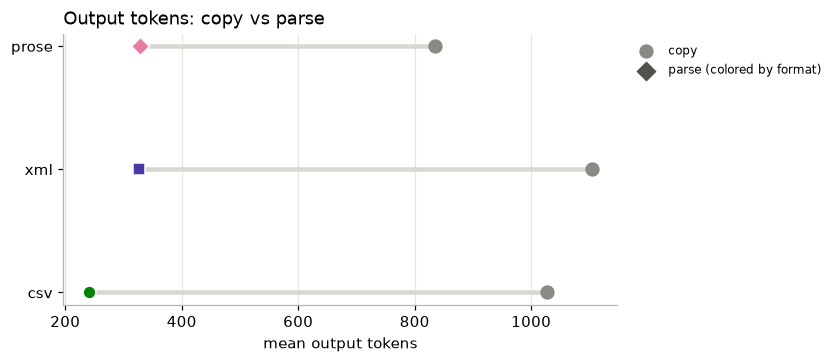

,copy,parse,parse / copy
data_format,,,
csv,1027.0,240.0,0.23
xml,1105.0,326.0,0.30
prose,835.0,328.0,0.39


### claude-haiku-4-5

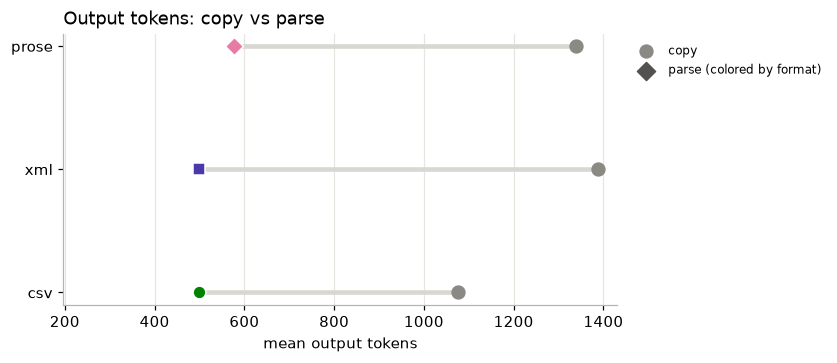

,copy,parse,parse / copy
data_format,,,
csv,1076.0,500.0,0.46
xml,1387.0,500.0,0.36
prose,1339.0,577.0,0.43


In [11]:
def section6(model):
    attempts = attempts_by_model[model]
    copy_means = valid[valid["model"] == model].groupby(["task_id", "data_format"])["output_tokens"].mean()
    twin_ids = attempts["task_id"].str.removesuffix("_parse").str.replace("t2", "t1", n=1)
    parse_means = attempts.assign(task_id=twin_ids).groupby(["task_id", "data_format"])["output_tokens"].mean()
    copy_vs_parse = pd.DataFrame({"copy": copy_means, "parse": parse_means}).dropna().groupby("data_format").mean().loc[DATA_FORMATS].round(0)
    copy_vs_parse["parse / copy"] = (copy_vs_parse["parse"] / copy_vs_parse["copy"]).round(2)

    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    y = np.arange(len(DATA_FORMATS))
    ax.hlines(y, copy_vs_parse["parse"], copy_vs_parse["copy"], color="#d8d7d1", linewidth=3, zorder=1)
    ax.scatter(copy_vs_parse["copy"], y, s=70, color="#8a8984", zorder=2, label="copy")
    for i, d in enumerate(DATA_FORMATS):
        ax.scatter(copy_vs_parse.loc[d, "parse"], i, s=70, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
                   edgecolor="white", linewidth=1)
    ax.scatter([], [], s=70, color="#52514e", marker="D", label="parse (colored by format)")
    ax.set_yticks(y, DATA_FORMATS)
    if model == CLAUDE:
        # Start where Qwen's chart (eda1's saved image) starts, so the two are easier to compare:
        # its data spans 240-1105 tokens, and matplotlib pads that by 5% on each side.
        ax.set_xlim(left=240 - 0.05 * (1105 - 240))
    ax.set_xlabel("mean output tokens")
    ax.set_title("Output tokens: copy vs parse", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.show()
    display(copy_vs_parse)

for_each_model(section6, "## 6.")

## 7. Parse version: did the code run on new data?

In [12]:
def section7(model):
    rows = parse_by_model[model]
    rows["code ran on new data"] = rows["passed_all"] | ((rows["tests_passed"] == 1) & rows["copied"])
    rows["uses pandas"] = rows["code_text"].str.contains("import pandas")
    rows["uses removed pandas call"] = rows["code_text"].str.contains("compat.StringIO")
    display(rows.groupby("data_format")[["code ran on new data", "uses pandas", "uses removed pandas call"]]
            .mean().round(2).loc[DATA_FORMATS])

for_each_model(section7, "## 7.")

### qwen2.5-coder:7b

*Raw replies aren't on this machine; saved output from eda1.ipynb:*

,code ran on new data,uses pandas,uses removed pandas call
data_format,,,
csv,0.52,0.32,0.3
xml,0.82,0.00,0.0
prose,0.52,0.00,0.0


### claude-haiku-4-5

,code ran on new data,uses pandas,uses removed pandas call
data_format,,,
csv,0.58,0.0,0.0
xml,0.67,0.0,0.0
prose,0.60,0.0,0.0


## 8. Claude replies that call an LLM

Not in eda1. On informal prompts Claude often wrote code that asks the Claude API for the answer instead of
computing it. The tests run without an API key, so this code always fails.

In [13]:
claude_rows = responses[responses["model"] == CLAUDE].copy()
claude_rows["kind"] = np.where(claude_rows["task_id"].str.endswith("_parse"), "parse", "copy")
claude_rows["calls LLM"] = [bool(re.search(r"anthropic|openai", raw_path(r).read_text(encoding="utf-8"), re.I))
                            for r in claude_rows.itertuples()]
print(f"{(claude_rows['calls LLM'] & ~claude_rows['passed_all']).sum()} of "
      f"{(~claude_rows['passed_all']).sum()} failed Claude replies call an LLM")
claude_rows.groupby(["format", "kind"]).agg(
    replies=("calls LLM", "size"),
    call_llm=("calls LLM", "sum"),
    passed_all=("passed_all", "mean"),
).round(2)

105 of 113 failed Claude replies call an LLM


replies  call_llm  passed_all
format     kind                                
informal   copy        90        44        0.74
           parse       90        83        0.03
structured copy        90         0        1.00
           parse       90         0        0.97

## Summary

- Input tokens: nearly the same for both models (same prompts); Claude's tokenizer counts 1–9% more, most on prose. XML ≈ 2.3× the input of CSV for both.
- Output (copy version): Claude writes more than Qwen in every format. Format effect differs: Qwen's prose is its *shortest* output (836 vs 1,043 CSV), Claude's prose is among its *longest* (1,341 vs 1,069 CSV); XML is longest for both.
- Total (copy version): CSV is cheapest for Claude; for Qwen, CSV and prose are about even.
- Storage style drives output for both: dicts with keys ≈ 1,310 tokens for Claude (Qwen ≈ 1,120), tuples ≈ 800 (Qwen ≈ 730). It explains the prose difference: Qwen stored prose data mostly as tuples (29 of 48), Claude mostly as dicts (39 of 48).
- Parse version: Claude's output drops to 36–46% of the copy version (Qwen 23–39%), but stays about 2× Qwen's (≈ 500–580 vs ≈ 240–330 tokens).
- Parse version: Claude's code ran on new data 58–67% of the time (Qwen: XML 82%, CSV and prose 52%). Claude never used pandas; nearly all its failures are informal-prompt replies that call the Claude API (section 8). These replies also paste the prompt's rows into their API prompt, which is why eda1's copy check flags 83 Claude parse replies as copied (Qwen: 4) and sections 5–6 leave them out.
- Qwen's sections 4–7 are eda1's saved outputs, since its raw replies aren't in this repo.